# 02 Exploratory analysis of the simulated APP world
Goal: see what makes scam payments differ from legitimate payments, and how the world drifts.

In [1]:
import sys, pathlib, json, warnings; warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
def table(name):
    p = ROOT / 'reports' / 'tables' / name
    return pd.read_csv(p) if p.exists() else None

In [2]:
from presage.data.loaders import load_sim, load_features
df, acc = load_sim(); X = load_features(); cust = df.src_is_customer == 1
print(df.shape, 'victim payments:', int(df.is_app_fraud.sum()), 'prevalence 1:%d' % round(1/df[cust].is_app_fraud.mean()))
print(df.txn_type.value_counts().to_dict()); print(df[df.is_app_fraud==1].scam_type.value_counts().to_dict())

(390498, 25) victim payments: 950 prevalence 1:331
{'legit': 382274, 'mule_forward': 4936, 'cashout': 2338, 'scam': 950}
{'investment': 277, 'romance': 189, 'impersonation': 135, 'bank_impersonation': 111, 'ceo_fraud': 95, 'purchase': 62, 'family_impersonation': 56, 'invoice_redirection': 25}


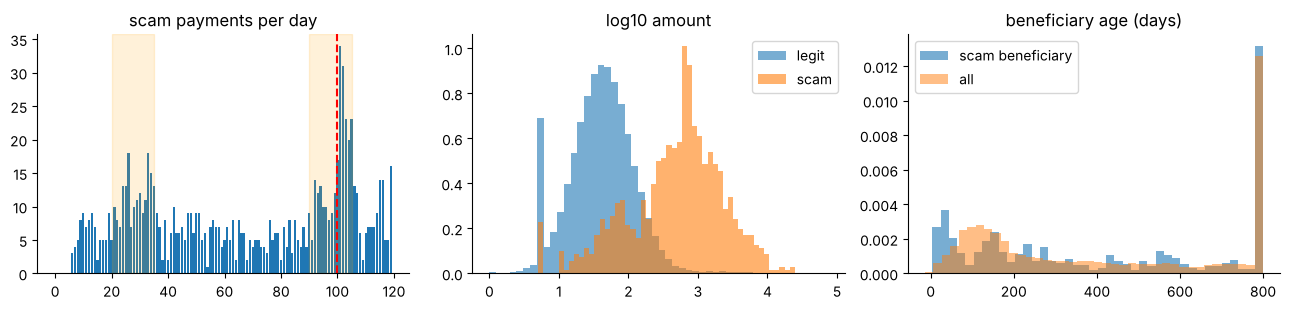

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
d = df[cust]; fr = d[d.is_app_fraud==1]
daily = d.groupby('day').is_app_fraud.sum(); ax[0].bar(daily.index, daily.values); ax[0].set_title('scam payments per day'); ax[0].axvline(100, c='r', ls='--'); [ax[0].axvspan(a,b,color='orange',alpha=.15) for a,b in ((20,35),(90,105))]
ax[1].hist(np.log10(d.amount), bins=50, alpha=.6, density=True, label='legit'); ax[1].hist(np.log10(fr.amount), bins=50, alpha=.6, density=True, label='scam'); ax[1].set_title('log10 amount'); ax[1].legend()
ax[2].hist((fr.dst_age_days).clip(upper=800), bins=40, alpha=.6, density=True, label='scam beneficiary'); ax[2].hist(d.dst_age_days.clip(upper=800), bins=40, alpha=.5, density=True, label='all'); ax[2].set_title('beneficiary age (days)'); ax[2].legend(); plt.tight_layout()

**Reading the plots.** Daily scam volume shows the recurring campaigns (orange) and the sudden-drift jump after day 100 (structuring creates more, smaller payments). Amounts and beneficiary age overlap heavily with legitimate behaviour, which is exactly the APP difficulty: no single feature is decisive.

In [4]:
from sklearn.metrics import roc_auc_score
cols = [c for c in X.columns if c != 'txn_id']
auc = pd.Series({c: roc_auc_score(df.is_app_fraud[cust], np.nan_to_num(X.loc[cust.values, c])) for c in cols})
print((auc - .5).abs().sort_values(ascending=False).head(12).index.map(lambda c: f'{c}: {auc[c]:.3f}').tolist())

['dst_in_cnt_total: 0.094', 'pct_balance: 0.898', 'log_amount: 0.897', 'amount: 0.897', 'dst_out_sum_7d: 0.889', 'dg_w_out: 0.889', 'dg_pr: 0.139', 'dst_avg_holding_s: 0.858', 'dst_fanin_total: 0.145', 'amt_to_hist_mean: 0.852', 'dst_fanout_total: 0.851', 'dg_in_deg: 0.153']


In [5]:
print(fr.groupby('scam_type').agg(n=('amount','size'), median_amount=('amount','median'), mean_session_s=('session_s','mean'), mean_failed_adds=('failed_ben_adds','mean'), mobile_share=('channel', lambda s:(s=='mobile').mean())).round(2))

                        n  median_amount  mean_session_s  mean_failed_adds  mobile_share
scam_type                                                                               
bank_impersonation    111        1982.62          286.16              0.27          0.54
ceo_fraud              95         739.23          173.79              0.34          0.51
family_impersonation   56         474.14          162.76              0.54          0.38
impersonation         135        1378.99          337.06              0.42          0.44
investment            277         650.68          174.47              0.40          0.42
invoice_redirection    25        1121.70          178.75              0.24          0.36
purchase               62         280.43          163.85              0.45          0.39
romance               189          71.59          162.78              0.33          0.35
